# Error Analysis and Data Integrity

We investigate potential data leakage and model failure cases.

First, we check for exact duplicate image content between the training and test sets. This helps identify whether repeated images could affect evaluation results.

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib

DATA_DIR = Path("../data/raw/metal_nut").resolve()

def image_hash(path):
    # Hash decoded RGB pixels, not filenames or PNG metadata
    from PIL import Image

    with Image.open(path) as img:
        rgb = img.convert("RGB")
        return hashlib.sha256(
            rgb.size[0].to_bytes(4, "big")
            + rgb.size[1].to_bytes(4, "big")
            + rgb.tobytes()
        ).hexdigest()

train_paths = sorted((DATA_DIR / "train/good").glob("*.png"))
test_paths = sorted((DATA_DIR / "test").rglob("*.png"))

train_hashes = defaultdict(list)

for path in train_paths:
    train_hashes[image_hash(path)].append(path)

duplicates = []

for path in test_paths:
    h = image_hash(path)
    for train_path in train_hashes.get(h, []):
        duplicates.append((train_path, path))

print("Training images:", len(train_paths))
print("Test images:", len(test_paths))
print("Exact train/test duplicates:", len(duplicates))

for train_path, test_path in duplicates[:10]:
    print(train_path.name, "<->", test_path)

Training images: 220
Test images: 115
Exact train/test duplicates: 0


## Near-Duplicate Detection

We use perceptual hashing (pHash) to identify visually similar images across the training and test sets.

Unlike cryptographic hashing, perceptual hashes can detect some image similarities even when pixel values are not identical. Flagged pairs are reviewed manually rather than automatically classified as duplicates.

In [2]:
import imagehash
from PIL import Image

train_hashes = []

for path in train_paths:
    with Image.open(path) as img:
        train_hashes.append(imagehash.phash(img.convert("RGB")))

suspicious_pairs = []
nearest_pairs = []

for test_path in test_paths:
    with Image.open(test_path) as img:
        test_hash = imagehash.phash(img.convert("RGB"))

    distances = [test_hash - h for h in train_hashes]
    nearest_index = min(range(len(distances)), key=distances.__getitem__)

    distance = distances[nearest_index]
    pair = (train_paths[nearest_index], test_path, distance)
    nearest_pairs.append(pair)

    if distance <= 5: suspicious_pairs.append(pair)

print("Potential near-duplicates (pHash distance <= 5):",
      len(suspicious_pairs))

print("\n10 most similar train/test pairs:")
for train_path, test_path, distance in sorted(
    nearest_pairs, key=lambda x: x[2]
)[:10]:
    print(
        f"Distance {distance:2d} | "
        f"{train_path.name} -> "
        f"{test_path.parent.name}/{test_path.name}"
    )

Potential near-duplicates (pHash distance <= 5): 4

10 most similar train/test pairs:
Distance  4 | 159.png -> color/015.png
Distance  4 | 073.png -> color/017.png
Distance  4 | 210.png -> good/018.png
Distance  4 | 143.png -> good/020.png
Distance  6 | 170.png -> bent/001.png
Distance  6 | 064.png -> bent/007.png
Distance  6 | 185.png -> bent/010.png
Distance  6 | 120.png -> bent/017.png
Distance  6 | 126.png -> color/020.png
Distance  6 | 064.png -> good/001.png


## Visual Inspection of Potential Near-Duplicates

Four train/test pairs have perceptual-hash distances of 5 or less.

We compare these pairs visually to determine whether they represent duplicate images or simply similar normal object appearances.

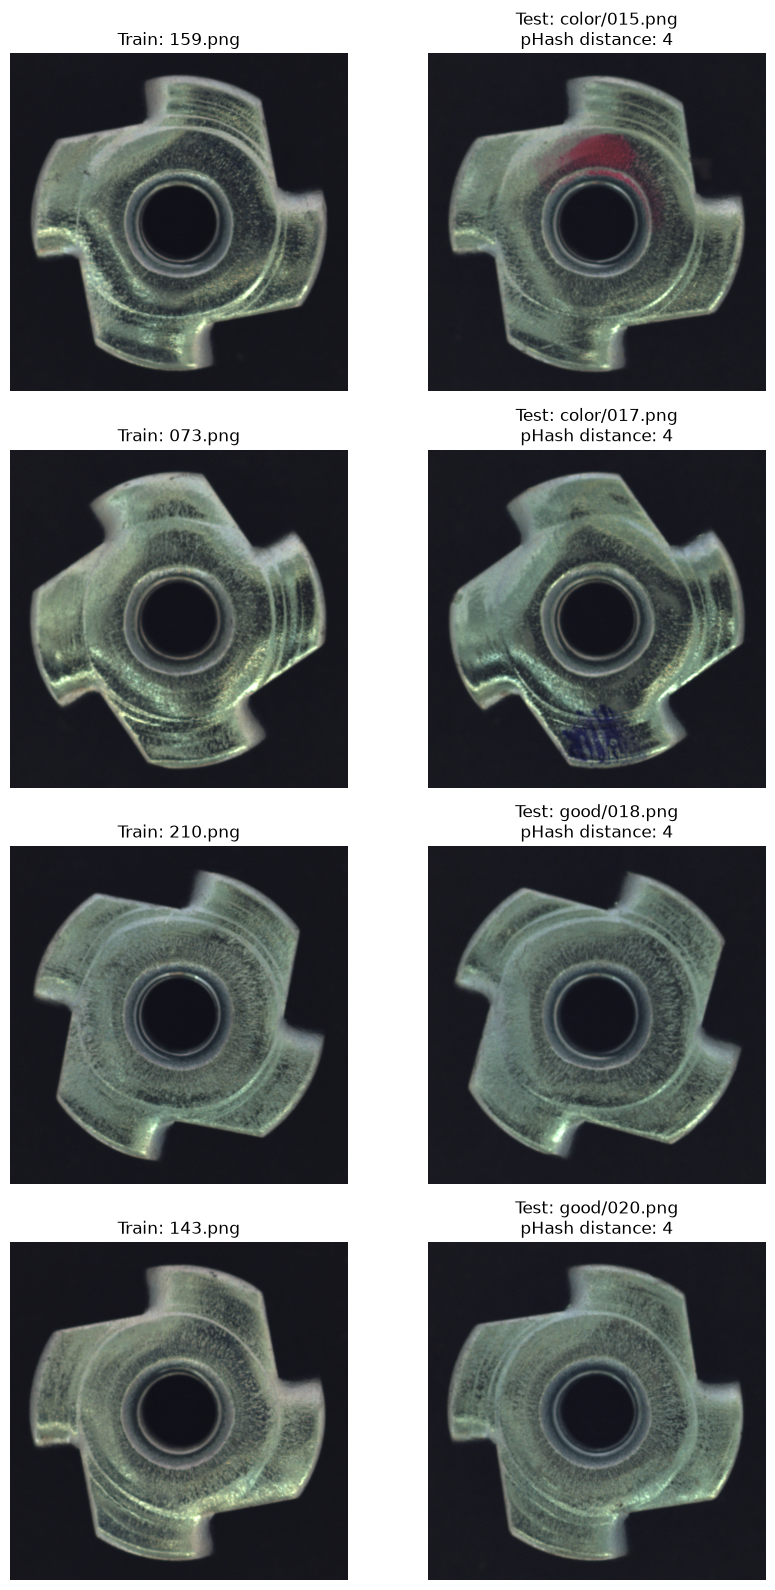

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    len(suspicious_pairs), 2,
    figsize=(9, 4 * len(suspicious_pairs))
)

for i, (train_path, test_path, distance) in enumerate(suspicious_pairs):
    with Image.open(train_path) as img:
        train_img = img.convert("RGB").copy()

    with Image.open(test_path) as img:
        test_img = img.convert("RGB").copy()

    axes[i, 0].imshow(train_img)
    axes[i, 0].set_title(f"Train: {train_path.name}")

    axes[i, 1].imshow(test_img)
    axes[i, 1].set_title(
        f"Test: {test_path.parent.name}/{test_path.name}\n"
        f"pHash distance: {distance}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Near-Duplicate Screening Results

- Exact train/test duplicates: 0
- Potential near-duplicate pairs (pHash distance ≤ 5): 4
- Minimum observed pHash distance: 4

Perceptual hashing flagged four visually similar pairs for manual inspection. Low pHash distances do not independently establish data leakage, especially because the dataset contains images of similar objects under controlled conditions.